# 01. Tổng quan Dự án & Lựa chọn Tập dữ liệu

> Notebook mở đầu trình bày bối cảnh thực tiễn, bài toán nghiên cứu, hai câu hỏi dẫn hướng (`RQ1`, `RQ2`), phương pháp tiếp cận, lộ trình 5 bước và kiểm toán dữ liệu gốc để lựa chọn bộ dữ liệu phù hợp.

### Bối cảnh & Vấn đề thực tiễn

Trên mạng lưới đường cao tốc đô thị, tình trạng ùn tắc hiếm khi bùng phát đồng loạt ở mọi tuyến đường cùng lúc mà thường khởi phát tại một số **nút thắt cổ chai** trọng yếu rồi lan truyền ngược dòng sang các đoạn kế cận.

Tuy nhiên, các hệ thống giám sát giao thông truyền thống chủ yếu cảnh báo dựa trên ngưỡng tại chỗ *sau khi vận tốc đã sụt giảm sâu*, khiến công tác điều tiết luôn ở thế bị động khi dòng xe đã dồn ứ.

### Chủ đề nghiên cứu & Hai Câu hỏi Lớn
* **Tên đề tài:** *Tín hiệu Tiền tắc nghẽn Hướng Vật lý cho Bài toán Dự báo Điểm nghẽn Cao tốc bằng Mạng Chú ý Đồ thị* (*Physics-Informed Pre-Congestion Signals for Freeway Bottleneck Forecasting with Graph Attention*).
* **Mục tiêu cốt lõi:** Xác định điều kiện tắc nghẽn hướng dữ liệu trực tiếp từ Biểu đồ cơ bản, trích xuất và kiểm chứng hệ chỉ báo tiền tắc nghẽn trên cửa sổ `60 phút`, và đánh giá mức độ cải thiện dự báo điểm tắc nghẽn tương lai khi đưa các chỉ báo này vào mô hình học trên đồ thị. Toàn bộ chuỗi phân tích từ Notebook `01` đến `05` hướng tới giải đáp trọn vẹn hai câu hỏi nghiên cứu:
  * **RQ1 (Xác định trạng thái tắc nghẽn & Tín hiệu tiền tắc nghẽn — `NB03` trên `PEMS08`):** *Làm thế nào xác định trạng thái tắc nghẽn và trích xuất các dấu hiệu tiền tắc nghẽn trực tiếp từ dữ liệu cảm biến đa biến?*
  * **RQ2 (Đóng góp của dấu hiệu tiền tắc nghẽn trong mô hình dự báo đồ thị — `NB04` trên `PEMS08`, kiểm chứng độc lập trên `PEMS04` ở `NB05`):** *Việc bổ sung các dấu hiệu tiền tắc nghẽn có giúp các mô hình dự báo đồ thị (gồm mô hình chú ý đồ thị) dự đoán điểm tắc nghẽn tương lai tốt hơn không, và từng dấu hiệu đóng góp ra sao?*

### Phương pháp tiếp cận & Hệ thống công cụ
* **Phân tích dữ liệu & cấu trúc đồ thị:** Sử dụng `Python 3.12`, `NumPy`, `Pandas`, `SciPy`, `NetworkX`, `Matplotlib`, `Seaborn` để kiểm toán chất lượng, làm sạch theo chuẩn **Chen et al. (2003)** và giải phẫu Biểu đồ cơ bản cùng đồ thị có hướng.
* **Kiểm định thống kê & mô hình dự báo:** Sử dụng `Scikit-learn` và thư viện học sâu trên đồ thị (cố định `SEED = 42`) để kiểm định giá trị cộng thêm của hệ chỉ báo tiền tắc nghẽn và đánh giá mức đóng góp của từng nhóm đặc trưng.

### Lộ trình thực hiện dự án (5 bước)

| Bước | Tệp Notebook | Câu hỏi & Quy trình thực hiện | Đầu ra chính |
| :---: | :--- | :--- | :--- |
| **01** | `01_Overview.ipynb` | Bộ dữ liệu PeMS nào đủ điều kiện về biến đo và cấu trúc mạng cho nghiên cứu? | Hồ sơ đối chiếu 4 tập PeMS và phân vai `PEMS08` / `PEMS04` |
| **02** | `02_Data_Cleaning_and_Interpolation.ipynb` | Dữ liệu thô có ẩn lỗi cảm biến hay không, và phục hồi theo Chen et al. (2003) ra sao? | Dữ liệu sạch `0` lỗi lưu tại `datasets/cleaned/` |
| **03** | `03_EDA_and_Bottleneck_Analysis.ipynb` | **RQ1 (thuần `PEMS08`):** Điều kiện tắc nghẽn tự tính từ Biểu đồ cơ bản, `7` chỉ báo tiền tắc nghẽn (`60p`) và đối chiếu đồ thị tĩnh vs. động (`In / Out`). | Bảng điểm tắc, đồ thị `.gexf`, `5` biểu đồ `RQ1` |
| **04** | `04_Modeling_and_Feature_Contribution.ipynb` | **RQ2 (`PEMS08`):** So sánh có kiểm soát giữa đặc trưng gốc và khi bổ sung `7` chỉ báo tiền tắc nghẽn; đánh giá đóng góp từng nhóm đặc trưng và trọng số chú ý đồ thị. | Bảng đối chứng mô hình, phân tích đóng góp đặc trưng |
| **05** | `05_Cross_Map_Validation_PEMS04.ipynb` | **Kiểm chứng độc lập (`PEMS04`):** Tự hiệu chỉnh ngưỡng từ Biểu đồ cơ bản `PEMS04` và xác nhận lại ích lợi của dấu hiệu tiền tắc nghẽn trên bản đồ mới. | Bảng và biểu đồ kiểm chứng tổng quát đa bản đồ |

---
## 1. Câu hỏi mở đầu: Bộ dữ liệu PeMS nào đủ điều kiện cho bài toán?

Từ hai câu hỏi nghiên cứu ở trên, yêu cầu tối thiểu đối với dữ liệu là phải ghi nhận đồng thời **cấu trúc kết nối có hướng giữa các trạm** và **diễn biến đa biến của dòng xe** (lưu lượng, mật độ/độ chiếm dụng mặt đường và vận tốc). Bộ sưu tập cảm biến giao thông công khai PeMS (Caltrans Performance Measurement System) hiện có 4 tập chuẩn là `PEMS03`, `PEMS04`, `PEMS07` và `PEMS08`.

Mỗi thư mục trong `datasets/data/` thường gồm:
* **Tệp `.npz`:** Mảng 3 chiều `(T, N, C)`, với `T` là số bước đo (chu kỳ **5 phút/bước**, tương ứng **288 bước/ngày**), `N` là số trạm cảm biến, `C` là số biến đo tại mỗi trạm.
* **Tệp `.csv`:** Danh sách cạnh có hướng theo chiều dòng xe (`from` → `to`) kèm trọng số khoảng cách (`cost` hoặc `distance`).
* **Tệp `.txt` (nếu có):** Bảng ánh xạ mã trạm gốc sang chỉ số mảng (chỉ xuất hiện khi chỉ số trong `.csv` không khớp trực tiếp `0..N-1`).

Trước hết, ta nạp nguyên bản cả 4 bộ dữ liệu để xem kích thước thực tế.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_DIR = Path("..").resolve() / "datasets" / "data"
FIG_DIR = Path("..").resolve() / "outputs" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "savefig.dpi": 300})
DATASETS = ["PEMS03", "PEMS04", "PEMS07", "PEMS08"]
FEATURES = ["Lưu lượng", "Độ chiếm dụng", "Vận tốc"]

raw = {}
for name in DATASETS:
    npz = np.load(DATA_DIR / name / f"{name}.npz")
    tensor = npz[npz.files[0]]
    edges = pd.read_csv(DATA_DIR / name / f"{name}.csv")
    edges.columns = edges.columns.str.strip().str.lower()
    raw[name] = {"tensor": tensor, "edges": edges}
    print(f"{name:6s} | shape={str(tensor.shape):15s} | edges={len(edges):3d}")

PEMS03 | shape=(26208, 358, 1) | edges=547
PEMS04 | shape=(16992, 307, 3) | edges=340
PEMS07 | shape=(28224, 883, 1) | edges=866
PEMS08 | shape=(17856, 170, 3) | edges=295


---
## 2. Đối chiếu cấu trúc không gian – thời gian của 4 bộ dữ liệu

Sau khi biết kích thước thô, câu hỏi nhỏ tiếp theo là: **Mỗi bộ dữ liệu kéo dài bao nhiêu ngày, đồ thị kết nối dày hay thưa, có ghi nhận đủ các biến đo lường cần thiết và khớp chỉ số trạm hay không?**

Ta tổng hợp các thông số cấu trúc gồm: thời lượng quan trắc (`T × 5 / 1440` ngày), số trạm (`N`), số cạnh (`E`), **bậc kết nối trung bình** (`2E / N` — số đầu nối trung bình gắn với mỗi trạm), số biến (`C`), và tính hợp lệ của chỉ số nút.

In [2]:
rows = []
for name, d in raw.items():
    T, N, C = d["tensor"].shape
    e = d["edges"]
    id_ok = e[["from", "to"]].min().min() >= 0 and e[["from", "to"]].max().max() < N
    rows.append({
        "Bộ dữ liệu": name, "Số bước": T, "Số ngày": round(T * 5 / 1440, 1),
        "Số trạm": N, "Số cạnh": len(e), "Bậc TB": round(2 * len(e) / N, 2),
        "Số biến": C, "Các biến": ", ".join(FEATURES[:C]),
        "Tổng điểm dữ liệu": f"{d['tensor'].size:,}",
        "Khớp chỉ số 0..N-1": "Có" if id_ok else "Không (mã gốc)",
    })

profile_df = pd.DataFrame(rows)
profile_df

,Bộ dữ liệu,Số bước,Số ngày,Số trạm,Số cạnh,Bậc TB,Số biến,Các biến,Tổng điểm dữ liệu,Khớp chỉ số 0..N-1
0,PEMS03,26208,91.0,358,547,3.06,1,Lưu lượng,"9,382,464",Không (mã gốc)
1,PEMS04,16992,59.0,307,340,2.21,3,"Lưu lượng, Độ chiếm dụng, Vận tốc","15,649,632",Có
2,PEMS07,28224,98.0,883,866,1.96,1,Lưu lượng,"24,921,792",Có
3,PEMS08,17856,62.0,170,295,3.47,3,"Lưu lượng, Độ chiếm dụng, Vận tốc","9,106,560",Có


Biểu đồ dưới đây đặt cả 4 tập dữ liệu trên cùng một hệ màu trung tính để trực quan hóa 4 khía cạnh đối chiếu: quy mô trạm – cạnh, độ dài chuỗi & số biến, mật độ kết nối đồ thị, và tỷ lệ giá trị `<= 0` ở kênh đầu tiên (`Lưu lượng`).

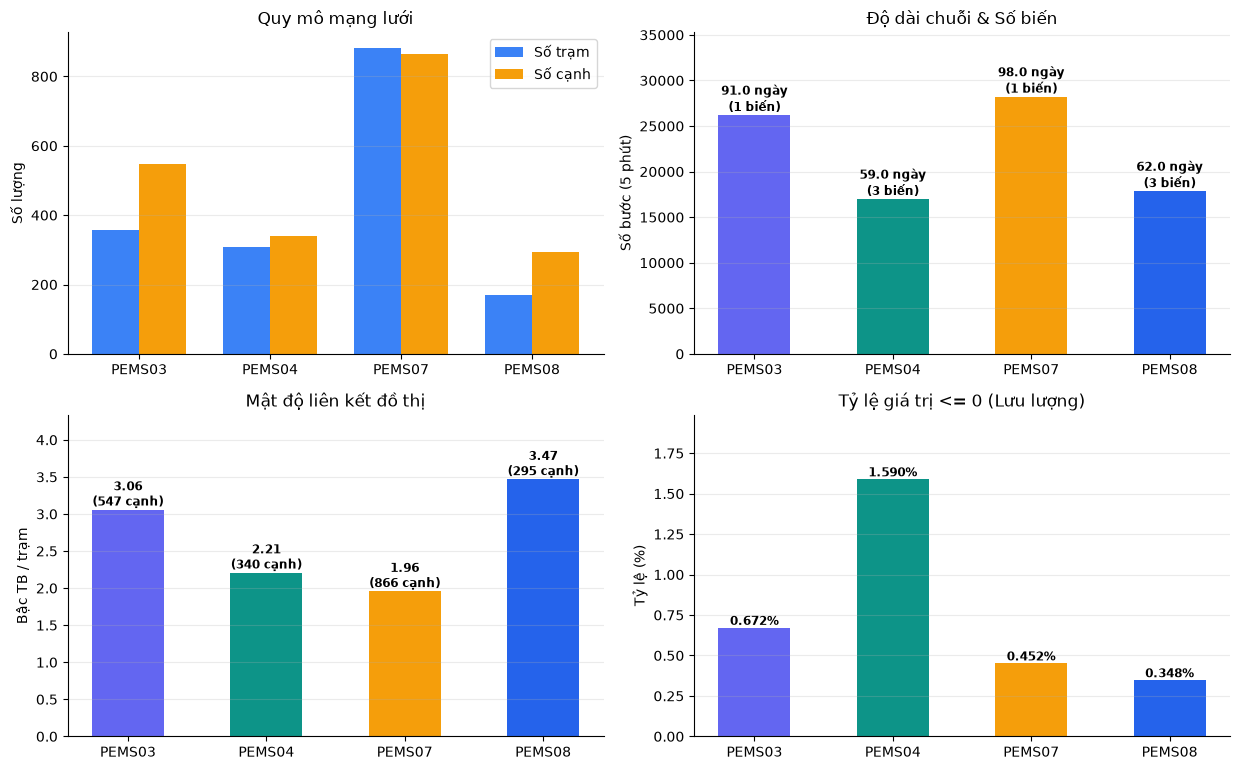

In [3]:
colors = ["#6366f1", "#0d9488", "#f59e0b", "#2563eb"]
zero_pcts = [100 * (raw[n]["tensor"][:, :, 0] <= 0).mean() for n in DATASETS]

def draw_bars(ax, vals, title, ylabel, labels):
    bars = ax.bar(DATASETS, vals, color=colors, width=0.52)
    for b, lbl in zip(bars, labels):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height(), lbl, ha="center", va="bottom", fontsize=8.5, fontweight="bold")
    ax.set(title=title, ylabel=ylabel, ylim=(0, max(vals) * 1.25))
    ax.grid(axis="y", alpha=0.25)

fig, axes = plt.subplots(2, 2, figsize=(12.5, 7.8))
x = np.arange(len(DATASETS))
axes[0, 0].bar(x - 0.18, profile_df["Số trạm"], 0.36, color="#3b82f6", label="Số trạm")
axes[0, 0].bar(x + 0.18, profile_df["Số cạnh"], 0.36, color="#f59e0b", label="Số cạnh")
axes[0, 0].set(xticks=x, xticklabels=DATASETS, ylabel="Số lượng", title="Quy mô mạng lưới")
axes[0, 0].legend(frameon=True); axes[0, 0].grid(axis="y", alpha=0.25)

draw_bars(axes[0, 1], profile_df["Số bước"], "Độ dài chuỗi & Số biến", "Số bước (5 phút)",
          [f"{r['Số ngày']} ngày\n({r['Số biến']} biến)" for _, r in profile_df.iterrows()])
draw_bars(axes[1, 0], profile_df["Bậc TB"], "Mật độ liên kết đồ thị", "Bậc TB / trạm",
          [f"{r['Bậc TB']:.2f}\n({r['Số cạnh']} cạnh)" for _, r in profile_df.iterrows()])
draw_bars(axes[1, 1], zero_pcts, "Tỷ lệ giá trị <= 0 (Lưu lượng)", "Tỷ lệ (%)",
          [f"{v:.3f}%" for v in zero_pcts])

plt.tight_layout()
fig.savefig(FIG_DIR / "nb01_dataset_overview.png", bbox_inches="tight")
plt.show()

> **Nhận xét (Từ cấu trúc thô của 4 bộ dữ liệu):**
>
> 1. **Điều kiện bắt buộc về số biến (`C`):**
>    * `PEMS03` (`91` ngày, `358` trạm) và `PEMS07` (`98` ngày, `883` trạm) có thời lượng dài hơn nhưng **chỉ chứa 1 biến là Lưu lượng (`C = 1`)**, thiếu hoàn toàn `Độ chiếm dụng` và `Vận tốc` — do đó không thể quan sát được tình trạng sụt giảm vận tốc hay mức độ bão hòa mặt đường. Ngoài ra, `PEMS03` còn dùng mã định danh gốc chưa quy chuẩn về `0..357`.
>    * Chỉ có **`PEMS04` và `PEMS08`** cung cấp **đủ 3 biến (`C = 3`)** và đánh chỉ số trạm đồng bộ.
>
> 2. **So sánh hai ứng viên `PEMS08` và `PEMS04`:**
>    * `PEMS08` có chuỗi thời gian dài hơn (`17.856` bước = `62` ngày so với `16.992` bước = `59` ngày của `PEMS04`), mật độ liên kết đồ thị dày hơn rõ rệt (**bậc TB `3.47`**, `295` cạnh trên `170` trạm), và tỷ lệ giá trị `<= 0` ở kênh Lưu lượng thấp hơn gần `4.6` lần (**`0.348%`** so với **`1.590%`**).
>    * `PEMS04` có số lượng trạm lớn hơn (`307` trạm, `340` cạnh) với cấu trúc thưa hơn (`bậc TB 2.21`), thuộc khu vực và khung thời gian khác.
>
> **Câu hỏi nghi vấn tiếp theo:**
>
> Về mặt vỏ cấu trúc, `PEMS08` và `PEMS04` đều đáp ứng yêu cầu. Nhưng **bên trong dữ liệu đo thực tế của từng biến có bị khuyết (`NaN`), có đồng nhất về thang đo hay ẩn chứa bất thường nào ở các giá trị bằng `0.0` hay không?**

---
## 3. Kiểm tra chất lượng & Phân phối giá trị gốc bên trong từng biến

Để trả lời câu hỏi trên, ta đi sâu vào giá trị số học của từng biến và cấu trúc trọng số cạnh:
* **Lưu lượng (Flow):** Tổng số xe đi qua mặt cắt cảm biến trong mỗi chu kỳ `5` phút (đơn vị: xe / 5 phút).
* **Độ chiếm dụng (Occupancy):** Tỷ lệ thời gian trong `5` phút mà cảm biến mặt đường bị xe che phủ (miền lý thuyết `[0, 1]`), phản ánh mật độ dồn ứ phương tiện.
* **Vận tốc (Speed):** Vận tốc trung bình của dòng xe qua trạm đo (đơn vị: dặm/giờ — `mph`).

Ta kiểm tra các chỉ số thống kê mô tả (`NaN`, tỷ lệ `<= 0`, `Min`, `Trung vị`, `TB`, `Std`, `Max`) và in mẫu tệp cạnh `.csv` của cả 4 tập.

In [4]:
stats = []
for name, d in raw.items():
    arr = d["tensor"]
    for f in range(arr.shape[2]):
        v = arr[:, :, f]
        stats.append({
            "Bộ dữ liệu": name, "Biến": FEATURES[f], "NaN": int(np.isnan(v).sum()),
            "<= 0 (%)": round(100 * (v <= 0).mean(), 3),
            "Min": round(float(v.min()), 2), "Trung vị": round(float(np.median(v)), 2),
            "TB": round(float(v.mean()), 2), "Std": round(float(v.std()), 2), "Max": round(float(v.max()), 2),
        })
pd.DataFrame(stats)

,Bộ dữ liệu,Biến,NaN,<= 0 (%),Min,Trung vị,TB,Std,Max
0,PEMS03,Lưu lượng,0,0.672,0.0,136.00,179.26,143.71,1852.00
1,PEMS04,Lưu lượng,0,1.590,0.0,180.00,211.70,158.07,919.00
2,PEMS04,Độ chiếm dụng,0,1.592,0.0,0.04,0.05,0.05,0.77
3,PEMS04,Vận tốc,0,0.000,3.0,65.60,63.47,8.36,85.20
4,PEMS07,Lưu lượng,0,0.452,0.0,304.00,308.52,188.25,1498.00
5,PEMS08,Lưu lượng,0,0.348,0.0,215.00,230.68,146.22,1147.00
6,PEMS08,Độ chiếm dụng,0,0.348,0.0,0.06,0.07,0.05,0.90
7,PEMS08,Vận tốc,0,0.000,3.0,64.90,63.76,6.65,82.30


In [10]:
for name, d in raw.items():
    print(f"=== 3 cạnh đầu của {name} ===")
    display(d["edges"].head(3))

=== 3 cạnh đầu của PEMS03 ===


,from,to,distance
0,317842,318711,0.872
1,318721,315955,1.322
2,315927,318236,1.222


=== 3 cạnh đầu của PEMS04 ===


,from,to,cost
0,73,5,352.6
1,5,154,347.2
2,154,263,392.9


=== 3 cạnh đầu của PEMS07 ===


,from,to,cost
0,721,445,0.790
1,542,480,2.575
2,770,702,0.926


=== 3 cạnh đầu của PEMS08 ===


,from,to,cost
0,9,153,310.6
1,153,62,330.9
2,62,111,332.9


Với hai bộ dữ liệu đủ 3 biến (`PEMS08` và `PEMS04`), ta vẽ biểu đồ mật độ phân phối (KDE) cho từng biến để kiểm tra mức độ tương đồng về thang đo và hình dạng phân phối trước khi phân vai huấn luyện và xác thực.

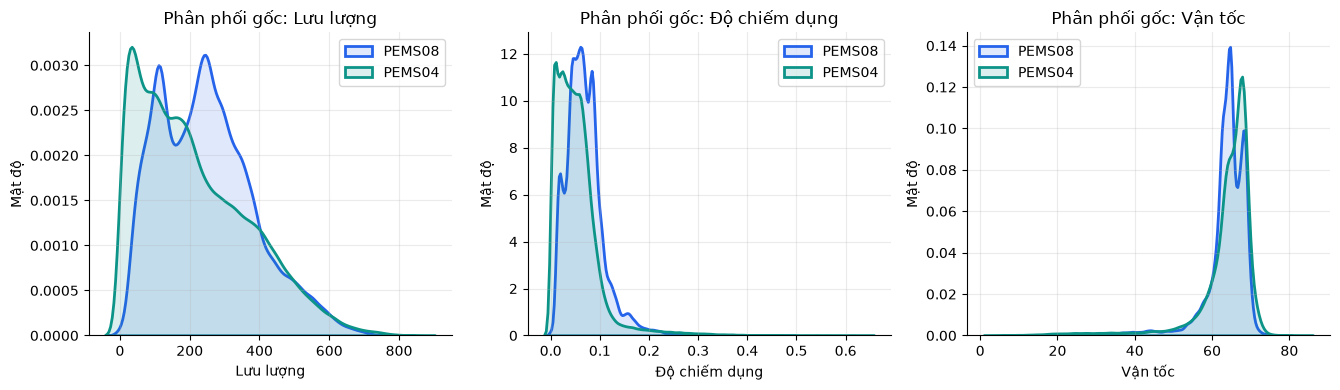

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4))
for f, fname in enumerate(FEATURES):
    for name, c in [("PEMS08", "#2563eb"), ("PEMS04", "#0d9488")]:
        sns.kdeplot(raw[name]["tensor"][:, :, f].ravel()[::30], ax=axes[f], color=c, lw=2, fill=True, alpha=0.14, label=name)
    axes[f].set(title=f"Phân phối gốc: {fname}", xlabel=fname, ylabel="Mật độ")
    axes[f].legend(frameon=True); axes[f].grid(alpha=0.25)

plt.tight_layout()
fig.savefig(FIG_DIR / "nb01_raw_feature_distributions.png", bbox_inches="tight")
plt.show()

> **Nhận xét (Chất lượng dữ liệu thô & Điểm bất thường phát hiện):**
>
> 1. **Không có giá trị `NaN` tường minh:**
>    Cả 4 tập đều đầy đủ ma trận số học (`NaN = 0`). Ở tệp cạnh `.csv`, trọng số khoảng cách của `PEMS03`/`PEMS07` tính theo dặm (~`0.8–2.6`), còn `PEMS04`/`PEMS08` tính theo mét (~`300–440`).
>
> 2. **Tín hiệu nghi vấn ở giá trị `0.0`:**
>    * Trên cả `PEMS04` (`1.590%` ở Lưu lượng và `1.592%` ở Độ chiếm dụng) lẫn `PEMS08` (`0.348%` ở cả hai biến), giá trị bằng `0.0` xuất hiện gần như đồng thời ở `Lưu lượng` và `Độ chiếm dụng`, nhưng kênh `Vận tốc` lại **hoàn toàn không có giá trị `0.0`** (`Min = 3.0 mph`).
>    * Thực tế vào ban đêm vắng xe vẫn có thể có khung 5 phút không ghi nhận xe nào qua trạm, nhưng cũng có khả năng cảm biến mất tín hiệu khiến lưu lượng/độ chiếm dụng rớt về `0.0` còn vận tốc giữ giá trị mặc định. Hiện tại chưa thể kết luận toàn bộ các điểm `0.0` là lỗi hay hợp lệ — cần kiểm toán riêng ở Notebook `02`.
>
> 3. **Tương đồng thang đo giữa `PEMS08` và `PEMS04`:**
>    Hai tập có phân phối `Vận tốc` rất gần nhau (trung bình `63.76 mph` trên `PEMS08` và `63.47 mph` trên `PEMS04`; trung vị quanh `64.9–65.6 mph`), đường `Lưu lượng` và `Độ chiếm dụng` cũng cùng bậc độ lớn (`Lưu lượng TB` lần lượt `230.68` và `211.70 xe/5 phút`). Điều này xác nhận tính hợp lý của việc dùng một tập làm chặng nghiên cứu chính và tập còn lại để kiểm chứng độc lập.

---
## 4. Kết luận phân vai dữ liệu & Câu hỏi dẫn sang Bước 02

### 4.1. Bảng phân vai toàn bộ 4 bộ dữ liệu

| Bộ dữ liệu | Quy mô (Bước / Trạm / Cạnh) | Bậc kết nối TB | Số biến | Tỷ lệ `<= 0` (Lưu lượng) | Vai trò được chọn | Luận giải dựa trên bằng chứng Bước 1–3 |
| :--- | :---: | :---: | :---: | :---: | :--- | :--- |
| **`PEMS03`** | 26.208 / 358 / 547 *(91 ngày)* | 3.06 | 1 (`Lưu lượng`) | 0.672% | **Loại** | Thiếu Độ chiếm dụng và Vận tốc; mã trạm gốc cần bảng ánh xạ `.txt`, không phân tích được sụt giảm vận tốc. |
| **`PEMS07`** | 28.224 / 883 / 866 *(98 ngày)* | 1.96 | 1 (`Lưu lượng`) | 0.452% | **Loại** | Thiếu Độ chiếm dụng và Vận tốc; cấu trúc cạnh thưa so với 883 trạm (bậc TB < 2). |
| **`PEMS08`** | 17.856 / 170 / 295 *(62 ngày)* | **3.47** | **3 (Đầy đủ)** | **0.348%** | **Khám phá & Huấn luyện chính** | Đủ 3 biến; chuỗi dài hơn (62 ngày); ít giá trị `0.0` bất thường nhất; đồ thị liên kết dày nhất (bậc TB 3.47). |
| **`PEMS04`** | 16.992 / 307 / 340 *(59 ngày)* | 2.21 | **3 (Đầy đủ)** | 1.590% | **Xác thực độc lập** | Đủ 3 biến; thuộc khu vực địa lý và khung thời gian khác; mạng lưới rộng (307 trạm) phù hợp kiểm chứng tính tổng quát hóa. |

### 4.2. Sản phẩm đầu ra của Notebook 01
* `outputs/figures/nb01_dataset_overview.png` — Biểu đồ đối chiếu cấu trúc 4 bộ dữ liệu.
* `outputs/figures/nb01_raw_feature_distributions.png` — Biểu đồ so sánh phân phối gốc 3 biến giữa `PEMS08` và `PEMS04`.

### 4.3. Câu hỏi nghi vấn chuyển sang Bước 02
Qua kiểm tra dữ liệu thô, ta phát hiện tỷ lệ giá trị bằng `0.0` chiếm `0.348%` trên `PEMS08` và `1.590%` trên `PEMS04` nhưng chưa tách bạch được bản chất của chúng. Do đó, câu hỏi mở ra cho bước tiếp theo là:
> *Trong số các giá trị bằng `0.0` ở kênh Lưu lượng và Độ chiếm dụng, **đâu là trạng thái đường vắng ban đêm hợp lệ cần giữ nguyên**, và **đâu là lỗi mất tín hiệu cảm biến cần phục hồi**? Với những đoạn mất tín hiệu ngắn hoặc kéo dài nhiều giờ, phương pháp nội suy nào vừa giảm sai số vừa bảo toàn đúng nhịp dao động gốc của chuỗi thời gian?*

---

**Tiếp theo:** [02. Làm sạch Dữ liệu & Nội suy Chuỗi Thời gian (`02_Data_Cleaning_and_Interpolation.ipynb`)](./02_Data_Cleaning_and_Interpolation.ipynb)